# 03 来店・注文明細ログの EDA

`input/logs.zip` 内の全 10 店舗・全 20 parquet を店舗ごとに読み、全行を集計する（サンプリングなし、ZIP 展開不要）。入力が大きいため実行には数分とメモリを要する。カラム別欠損、顧客・時間・待ち時間、数量・割引、売上との整合性を確認する。

**リーク注意**: ログは 2024 年までの実績であり、2025 年の同日ログを特徴量に使えない。結果は過去情報・仮説として扱う。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "input").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "input").is_dir(), "プロジェクトルートまたは eda/ から実行してください"
INPUT = ROOT / "input"
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.options.display.float_format = "{:,.2f}".format
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.figsize"] = (12, 4)
import io
import zipfile
import pyarrow.parquet as pq


In [2]:
zip_path=INPUT / "logs.zip"
assert zip_path.exists(), "input/logs.zip が必要です"
with zipfile.ZipFile(zip_path) as z:
    paths=sorted(x for x in z.namelist() if x.endswith(".parquet"))
    inventory=[]
    for path in paths:
        with z.open(path) as f:
            pf=pq.ParquetFile(io.BytesIO(f.read()))
            inventory.append({"file":path,"rows":pf.metadata.num_rows,"columns":len(pf.schema_arrow.names),"schema":", ".join(pf.schema_arrow.names)})
inventory=pd.DataFrame(inventory)
display(inventory)
print("全 parquet 行数:",f"{inventory.rows.sum():,}")

全 parquet 行数: 10,909,470


,file,rows,columns,schema
0,logs/S001/order_items.parquet,1006670,11,"order_id, group_id, store_id, date, order_time..."
1,logs/S001/visit_log.parquet,335479,24,"group_id, store_id, date, arrival_time, seat_t..."
2,logs/S002/order_items.parquet,866515,11,"order_id, group_id, store_id, date, order_time..."
3,logs/S002/visit_log.parquet,308798,24,"group_id, store_id, date, arrival_time, seat_t..."
4,logs/S003/order_items.parquet,964313,11,"order_id, group_id, store_id, date, order_time..."
5,logs/S003/visit_log.parquet,255933,24,"group_id, store_id, date, arrival_time, seat_t..."
6,logs/S004/order_items.parquet,1112487,11,"order_id, group_id, store_id, date, order_time..."
7,logs/S004/visit_log.parquet,285398,24,"group_id, store_id, date, arrival_time, seat_t..."
8,logs/S005/order_items.parquet,801335,11,"order_id, group_id, store_id, date, order_time..."
9,logs/S005/visit_log.parquet,214109,24,"group_id, store_id, date, arrival_time, seat_t..."


## 全件集計と欠損
1店舗ずつメモリに読み、店舗別の欠損・期間、客層、時間帯、明細、日×店舗×商品売上を集約する。

In [3]:
visit_summary=[]; order_summary=[]; v_missing=[]; o_missing=[]
segments=[]; visit_hours=[]; wait_by_store=[]; items=[]; order_hours=[]; coupons=[]; sales_parts=[]; order_daily_parts=[]; visit_daily_parts=[]
with zipfile.ZipFile(zip_path) as z:
    for store in sorted({p.split("/")[1] for p in paths}):
        def load(kind):
            with z.open(f"logs/{store}/{kind}.parquet") as f:
                return pq.read_table(io.BytesIO(f.read())).to_pandas()
        v=load("visit_log")
        v_missing.append(v.isna().sum().rename(store))
        visit_summary.append(dict(store_id=store, rows=len(v), min_date=v.date.min(), max_date=v.date.max(), groups=v.group_id.nunique(), duplicate_group=int(v.group_id.duplicated().sum()), seated=int(v.is_seated.sum()), left=int(v.is_left.sum()), guests=int(v.group_size.sum()), net_sales=v.net_sales_amount.sum(), wait_mean=v.wait_minutes.mean(), stay_mean=v.stay_minutes.mean()))
        segments.append(v.groupby(["store_id","segment"],dropna=False,observed=True).agg(groups=("group_id","size"),guests=("group_size","sum"),net_sales=("net_sales_amount","sum"),left=("is_left","sum")).reset_index())
        visit_hours.append(v.assign(hour=v.arrival_time.dt.hour).groupby(["store_id","hour"],dropna=False,observed=True).agg(groups=("group_id","size"),left=("is_left","sum"),wait_sum=("wait_minutes","sum"),wait_count=("wait_minutes","count")).reset_index())
        wait_by_store.append(v.groupby(["store_id","seat_source"],dropna=False,observed=True).agg(groups=("group_id","size"),wait_mean=("wait_minutes","mean"),stay_mean=("stay_minutes","mean")).reset_index())
        visit_daily_parts.append(v.groupby(["date","store_id"],observed=True).net_sales_amount.sum().rename("visit_net").reset_index())
        del v
        o=load("order_items")
        o_missing.append(o.isna().sum().rename(store))
        order_summary.append(dict(store_id=store,rows=len(o),min_date=o.date.min(),max_date=o.date.max(),quantity=o.quantity.sum(),list_sales=o.list_price_amount.sum(),discount=o.discount_amount.sum(),net_sales=o.net_sales_amount.sum(),bad_amount_rows=int((o.list_price_amount-o.discount_amount!=o.net_sales_amount).sum()),coupon_rows=int(o.applied_coupon_campaign_id.notna().sum())))
        items.append(o.groupby(["store_id","item_id"],observed=True).agg(lines=("item_id","size"),quantity=("quantity","sum"),net_sales=("net_sales_amount","sum"),discount=("discount_amount","sum")).reset_index())
        order_hours.append(o.assign(hour=o.order_time.dt.hour).groupby(["store_id","hour"],observed=True).agg(lines=("item_id","size"),quantity=("quantity","sum"),net_sales=("net_sales_amount","sum")).reset_index())
        coupons.append(o.groupby("applied_coupon_campaign_id",dropna=False,observed=True).agg(lines=("item_id","size"),quantity=("quantity","sum"),discount=("discount_amount","sum"),net_sales=("net_sales_amount","sum")).reset_index())
        sales_parts.append(o.groupby(["date","store_id","item_id"],observed=True).net_sales_amount.sum().rename("log_net").reset_index())
        order_daily_parts.append(o.groupby(["date","store_id"],observed=True).net_sales_amount.sum().rename("order_net").reset_index())
        del o
        print(store, "完了")
visits=pd.DataFrame(visit_summary); orders=pd.DataFrame(order_summary)
display(visits); display(orders)
print("来店ログ 欠損数（全店舗合計）"); display(pd.concat(v_missing,axis=1).sum(axis=1).to_frame("missing"))
print("注文明細 欠損数（全店舗合計）"); display(pd.concat(o_missing,axis=1).sum(axis=1).to_frame("missing"))
print("Totals:", visits[["rows","seated","left","guests"]].sum().to_dict(),orders[["rows","quantity","net_sales","discount","bad_amount_rows"]].sum().to_dict())

S001 完了
S002 完了
S003 完了
S004 完了
S005 完了
S006 完了
S007 完了
S008 完了
S009 完了
S010 完了
来店ログ 欠損数（全店舗合計）
注文明細 欠損数（全店舗合計）
Totals: {'rows': 2491880, 'seated': 2337482, 'left': 154398, 'guests': 5597867} {'rows': 8417590, 'quantity': 10045388, 'net_sales': 6255595849, 'discount': 10620191, 'bad_amount_rows': 0}


,store_id,rows,min_date,max_date,groups,duplicate_group,seated,left,guests,net_sales,wait_mean,stay_mean
0,S001,335479,2022-01-01,2024-12-31,335479,0,302739,32740,698857,"751,903,554.00",3.70,62.54
1,S002,308798,2022-01-01,2024-12-31,308798,0,293032,15766,581787,"638,998,882.00",2.17,56.27
2,S003,255933,2022-01-01,2024-12-31,255933,0,228881,27052,675675,"721,893,395.00",3.77,69.25
3,S004,285398,2022-01-01,2024-12-31,285398,0,249291,36107,793500,"834,023,019.00",4.74,70.20
4,S005,214109,2022-01-01,2024-12-31,214109,0,204652,9457,518680,"599,744,387.00",1.53,66.35
5,S006,162109,2022-01-01,2024-12-31,162109,0,161552,557,354110,"436,257,469.00",0.15,66.27
6,S007,193307,2022-01-01,2024-12-31,193307,0,190114,3193,449248,"540,727,217.00",0.69,67.06
7,S008,227188,2022-01-01,2024-12-31,227188,0,225940,1248,437030,"506,495,573.00",0.25,55.18
8,S009,151785,2022-01-01,2024-12-31,151785,0,150621,1164,357926,"431,118,221.00",0.27,66.92
9,S010,357774,2022-01-01,2024-12-31,357774,0,330660,27114,731054,"794,434,132.00",2.95,61.53


,store_id,rows,min_date,max_date,quantity,list_sales,discount,net_sales,bad_amount_rows,coupon_rows
0,S001,1006670,2022-01-01,2024-12-31,1190121,752334360,430806,751903554,0,12964
1,S002,866515,2022-01-01,2024-12-31,988411,639688960,690078,638998882,0,14221
2,S003,964313,2022-01-01,2024-12-31,1178876,724173120,2279725,721893395,0,32344
3,S004,1112487,2022-01-01,2024-12-31,1369040,836790660,2767641,834023019,0,39972
4,S005,801335,2022-01-01,2024-12-31,974151,601295880,1551493,599744387,0,22536
5,S006,596023,2022-01-01,2024-12-31,714587,436588820,331351,436257469,0,10056
6,S007,731885,2022-01-01,2024-12-31,885178,541064180,336963,540727217,0,10336
7,S008,684457,2022-01-01,2024-12-31,780304,507381920,886347,506495573,0,16617
8,S009,579569,2022-01-01,2024-12-31,702999,432006800,888579,431118221,0,13816
9,S010,1074336,2022-01-01,2024-12-31,1261721,794891340,457208,794434132,0,13757


,missing
group_id,0
store_id,0
date,0
arrival_time,0
seat_time,154398
order_time,154398
departure_time,154398
left_time,2337482
group_size,0
segment,0


,missing
order_id,0
group_id,0
store_id,0
date,0
order_time,0
item_id,0
quantity,0
list_price_amount,0
discount_amount,0
net_sales_amount,0


## 来店の客層・時間帯・待ち時間

待ち時間の平均は欠損を除く。離脱率は対象となる全来店組を分母とする。


,groups,guests,net_sales,left,left_rate,net_per_group
segment,,,,,,
family,621041,2317700,"2,496,889,103.00",89371,0.14,"4,020.49"
worker,572570,967383,"976,264,622.00",34465,0.06,"1,705.06"
couple,469154,938308,"1,119,228,672.00",10056,0.02,"2,385.63"
senior,349057,505438,"614,144,139.00",4140,0.01,"1,759.44"
student,299073,688053,"841,372,205.00",12597,0.04,"2,813.27"
single,180985,180985,"207,697,108.00",3769,0.02,"1,147.59"


,store_id,seat_source,groups,wait_mean,stay_mean
0,S001,immediate,179412,0.00,60.99
1,S001,queue,123327,7.18,64.79
2,S001,NaN,32740,10.83,NaN
0,S002,immediate,194049,0.00,56.58
1,S002,queue,98983,5.31,55.65
2,S002,NaN,15766,9.15,NaN
0,S003,immediate,161527,0.00,66.11
1,S003,queue,67354,8.93,76.80
2,S003,NaN,27052,13.44,NaN
0,S004,immediate,136921,0.00,67.13


,hour,groups,left,wait_sum,wait_count,left_rate,mean_wait
0,10,104107,77,"1,945.00",104107,0.00,0.02
1,11,254369,8000,"251,852.00",254369,0.03,0.99
2,12,323106,32458,"1,112,798.00",323106,0.10,3.44
3,13,245348,16740,"657,181.00",245348,0.07,2.68
4,14,173362,6539,"259,135.00",173362,0.04,1.49
5,15,171529,7034,"279,064.00",171529,0.04,1.63
6,16,182511,7343,"290,237.00",182511,0.04,1.59
7,17,260090,15632,"590,979.00",260090,0.06,2.27
8,18,282663,32472,"1,236,015.00",282663,0.11,4.37
9,19,242043,21512,"905,496.00",242043,0.09,3.74


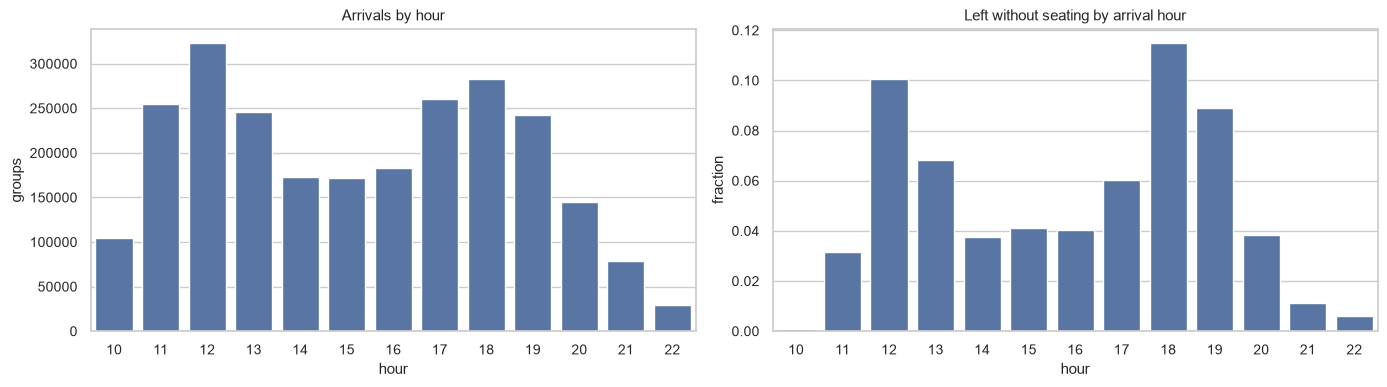

In [4]:
seg=pd.concat(segments).groupby("segment",dropna=False,observed=True)[["groups","guests","net_sales","left"]].sum(); seg["left_rate"]=seg.left/seg.groups; seg["net_per_group"]=seg.net_sales/seg.groups; display(seg.sort_values("groups",ascending=False))
wait=pd.concat(wait_by_store); display(wait)
hour=pd.concat(visit_hours).groupby("hour",as_index=False)[["groups","left","wait_sum","wait_count"]].sum(); hour["left_rate"]=hour.left/hour.groups; hour["mean_wait"]=hour.wait_sum/hour.wait_count
display(hour)
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.barplot(data=hour,x="hour",y="groups",ax=ax[0]); ax[0].set(title="Arrivals by hour",ylabel="groups"); sns.barplot(data=hour,x="hour",y="left_rate",ax=ax[1]); ax[1].set(title="Left without seating by arrival hour",ylabel="fraction"); plt.tight_layout();plt.show()
print("待ち時間の平均は欠損を除く。離脱率は対象となる全来店組を分母とする。")

## 注文商品・割引・時間帯

,item_id,lines,quantity,net_sales,discount,item_name,category,available_daypart,menu_type,season_code,campaign_tag
1,M002,1813217,3203943,807877150,0,Drink Bar (With Main),drink_bar,all_day,core,NaN,NaN
16,M017,192301,199001,235509890,357790,Pepper Steak Plate,main,all_day,core,NaN,NaN
9,M010,206397,214509,234212799,365881,Stewed Beef Omelet Rice,main,all_day,core,NaN,NaN
6,M007,218148,228383,225978870,403860,Cheese In Hamburg,main,all_day,core,NaN,NaN
8,M009,207891,215849,224575898,310792,Seafood Cream Pasta,main,all_day,core,NaN,NaN
2,M003,213574,222632,211272170,370600,Classic Hamburg Steak,main,all_day,core,NaN,NaN
3,M004,201532,208620,204373376,300184,Chicken Grill Plate,main,all_day,core,NaN,NaN
7,M008,204297,211674,202981603,297087,Miso Butter Chicken,main,all_day,core,NaN,NaN
11,M012,214767,223664,202965301,316879,Gratin Doria,main,all_day,core,NaN,NaN
15,M016,203027,210731,195728138,273962,Avocado Taco Rice,main,all_day,core,NaN,NaN


,lines,quantity,net_sales,discount
category,,,,
main,3739985,3897806,3789154297,5692453
drink_bar,1850556,3268461,829976390,0
lunch,764989,784848,621753434,1145506
side,1093728,1115329,475114180,0
dessert,640037,640441,324264983,3283247
kids,328295,338503,215332565,498985


,lines,quantity,discount,net_sales
applied_coupon_campaign_id,,,,
<NA>,8230971,9854168,0,6134049470
RULE_RAINY_DESSERT,57064,57111,1754317,27437143
RULE_FAMILY_WEEKEND,54336,57864,5692453,51232077
RULE_DESSERT_FAIR,42571,42599,1528930,20283890
RULE_WEEKDAY_LUNCH,17613,18092,1145506,13169564
RULE_KIDS_SMILE,15035,15554,498985,9423705


,hour,lines,quantity,net_sales
0,10,298448,361501,232673133
1,11,746537,874199,533071506
2,12,950492,1104210,673745908
3,13,845233,984119,597874104
4,14,630254,751743,458073907
5,15,621896,757204,471045457
6,16,647139,787785,490260720
7,17,835081,1011575,634109292
8,18,885463,1058964,675087329
9,19,847762,1014612,646099420


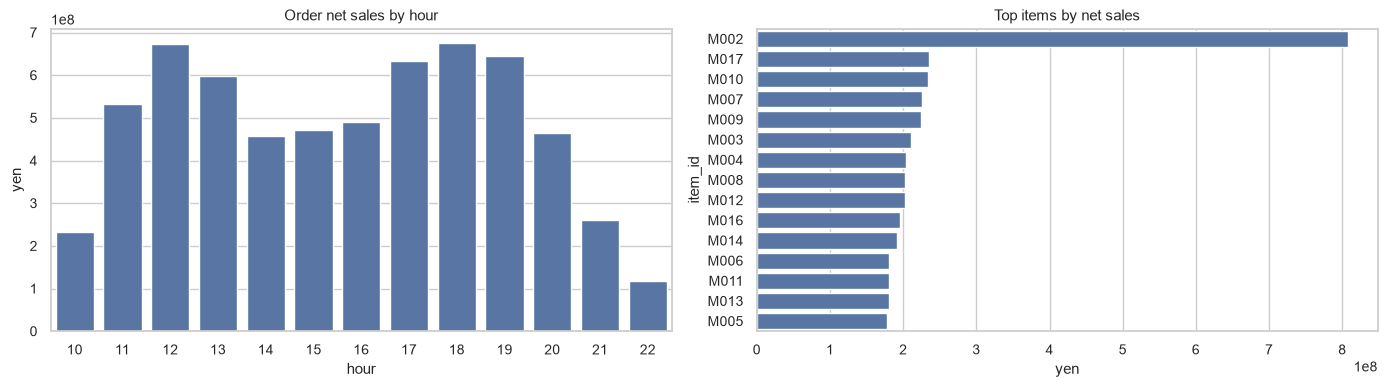

In [5]:
menus=pd.read_csv(INPUT/"menus.csv")
item_summary=pd.concat(items).groupby("item_id",as_index=False)[["lines","quantity","net_sales","discount"]].sum().merge(menus,on="item_id",validate="one_to_one")
display(item_summary.sort_values("net_sales",ascending=False).head(20))
display(item_summary.groupby("category",observed=True)[["lines","quantity","net_sales","discount"]].sum().sort_values("net_sales",ascending=False))
coupon_summary=pd.concat(coupons).groupby("applied_coupon_campaign_id",dropna=False,observed=True)[["lines","quantity","discount","net_sales"]].sum().sort_values("lines",ascending=False); display(coupon_summary)
oh=pd.concat(order_hours).groupby("hour",as_index=False)[["lines","quantity","net_sales"]].sum(); display(oh)
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.barplot(data=oh,x="hour",y="net_sales",ax=ax[0]); ax[0].set(title="Order net sales by hour",ylabel="yen"); sns.barplot(data=item_summary.nlargest(15,"net_sales"),x="net_sales",y="item_id",ax=ax[1]); ax[1].set(title="Top items by net sales",xlabel="yen"); plt.tight_layout(); plt.show()

## 売上の突合
注文明細の値引き後金額を日×店舗×商品で合算し train と照合。注文明細のないキーは 0 円とする。来店ログも日×店舗で比較する。

In [6]:
train=pd.read_csv(INPUT/"train.csv",parse_dates=["date"])
log_sales=pd.concat(sales_parts,ignore_index=True)
check=train.merge(log_sales,on=["date","store_id","item_id"],how="outer",validate="one_to_one",indicator=True)
check[["sales_amount","log_net"]]=check[["sales_amount","log_net"]].fillna(0)
check["difference"]=check.sales_amount-check.log_net
print("Train vs order merge:",check._merge.value_counts().to_dict())
print("日×店舗×商品: 不一致数 / 最大絶対差 / 絶対差合計:", int((check.difference.abs()>1e-6).sum()), check.difference.abs().max(),check.difference.abs().sum())
display(check.loc[check.difference.abs()>1e-6].head(10))
vc=pd.concat(visit_daily_parts).merge(pd.concat(order_daily_parts),on=["date","store_id"],how="outer",validate="one_to_one").fillna({"visit_net":0,"order_net":0})
vc["difference"]=vc.visit_net-vc.order_net
print("来店 vs 注文の日×店舗: 不一致数 / 最大絶対差:",int((vc.difference.abs()>1e-6).sum()),vc.difference.abs().max())
display(vc.loc[vc.difference.abs()>1e-6].head(10))

Train vs order merge: {'both': 676728, 'left_only': 243912, 'right_only': 0}
日×店舗×商品: 不一致数 / 最大絶対差 / 絶対差合計: 0 0.0 0.0
来店 vs 注文の日×店舗: 不一致数 / 最大絶対差: 0 0.0


,date,store_id,item_id,sales_amount,log_net,_merge,difference


,date,store_id,visit_net,order_net,difference


## 次の検討
- 待ち時間・客層・時間帯や数量を過去期間から集約し、店舗や商品ごとの季節性を検討する。
- 来店・注文は売上と同時に生成される実績。2025 年の予測や時系列検証では、予測時点より後の実績を使わない。
- 欠損には非着席時の着席・退店時刻など、構造的に発生するものがある。単純補完する前に意味を確認する。